# Bike Rental Demand Prediction

## Name: Yahya Jamal

## Roll No: 54 | Batch: C4

### Aim

Predict the number of daily bike rentals using Linear Regression and Ridge.
Predict Low or High demand using a Decision Tree and SVM.

This version follows the style of my lab notebooks: small cells, simple variables,
direct model training, and separate graphs. No custom functions or pipelines are needed.
Model settings are fixed examples, not tuned settings. Results may differ from the original notebook.

## 1. Import Libraries

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

## 2. Load Dataset

In [6]:
df = pd.read_csv(
    r'C:\Users\LENOVO\Documents\ChatGPT\ml\Bike_Rental_Demand_Project\Bike_Rental_Demand_Project\day.csv'
)

df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [7]:
df.shape

(731, 16)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 91.5 KB


In [9]:
df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


## 3. Check Missing Values and Duplicates

In [10]:
df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df = df.drop_duplicates()
df['dteday'] = pd.to_datetime(df['dteday'])# this puts the days in date order.
df = df.sort_values('dteday')
df = df.reset_index(drop=True)

## 4. Select Input and Output Columns

In [13]:
X = df[['temp', 'hum', 'windspeed', 'season', 'yr', 'mnth',
        'holiday', 'weekday', 'workingday', 'weathersit']]

y = df['cnt']

print('Input Shape:', X.shape)
print('Output Shape:', y.shape)

Input Shape: (731, 10)
Output Shape: (731,)


## 5. Split Training and Testing Data

In [14]:
split = int(len(df) * 0.80)

X_train = X.iloc[:split].copy()
X_test = X.iloc[split:].copy()

y_train = y.iloc[:split].copy()
y_test = y.iloc[split:].copy()

train_df = df.iloc[:split].copy()
test_df = df.iloc[split:].copy()

print('Training samples:', len(X_train))
print('Testing samples:', len(X_test))
print('Last training date:', train_df['dteday'].max())
print('First testing date:', test_df['dteday'].min())

Training samples: 584
Testing samples: 147
Last training date: 2012-08-06 00:00:00
First testing date: 2012-08-07 00:00:00


## 6. Data Visualization

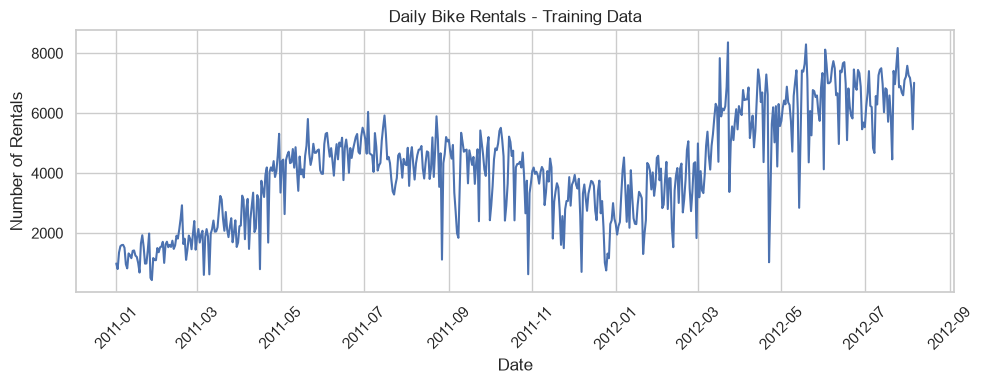

In [15]:
plt.figure(figsize=(10, 4))
plt.plot(train_df['dteday'], train_df['cnt'])
plt.xlabel('Date')
plt.ylabel('Number of Rentals')
plt.title('Daily Bike Rentals - Training Data')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

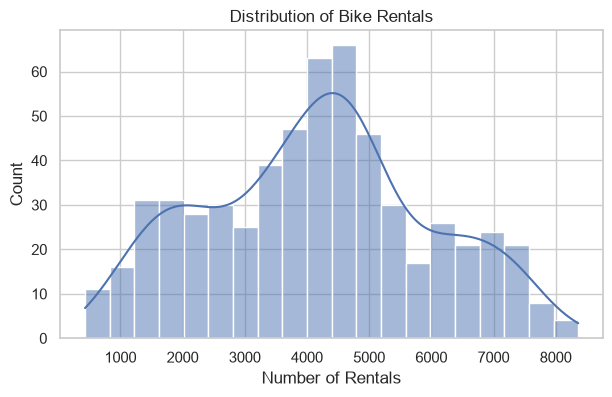

In [16]:
plt.figure(figsize=(7, 4))
sns.histplot(train_df['cnt'], bins=20, kde=True)
plt.title('Distribution of Bike Rentals')
plt.xlabel('Number of Rentals')
plt.show()

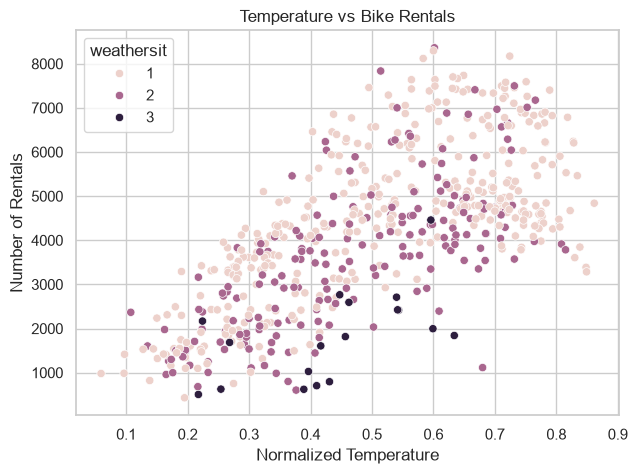

In [17]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=train_df, x='temp', y='cnt', hue='weathersit')
plt.xlabel('Normalized Temperature')
plt.ylabel('Number of Rentals')
plt.title('Temperature vs Bike Rentals')
plt.show()

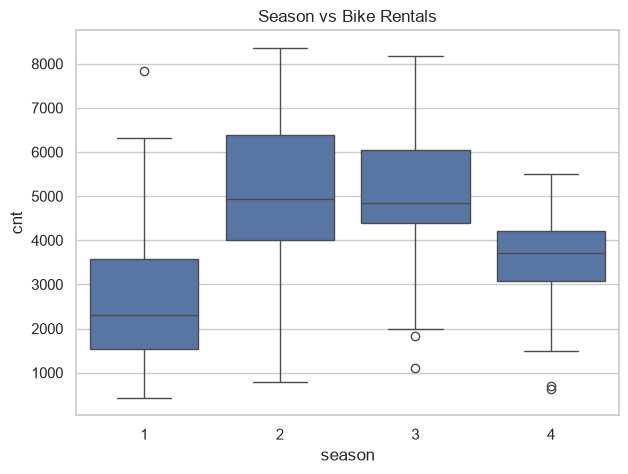

In [18]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=train_df, x='season', y='cnt')
plt.title('Season vs Bike Rentals')
plt.show()

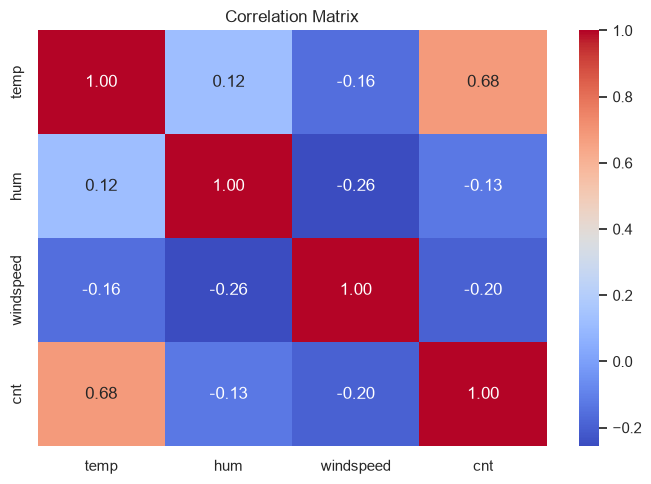

In [19]:
correlation = train_df[['temp', 'hum', 'windspeed', 'cnt']].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

## 7. Encode Categories

In [20]:
categorical_columns = ['season', 'mnth', 'weekday', 'weathersit']

X_train_encoded = pd.get_dummies(X_train, columns=categorical_columns, dtype=int) #pd.getdummies -> one hot encoding k liye
X_test_encoded = pd.get_dummies(X_test, columns=categorical_columns, dtype=int)

X_test_encoded = X_test_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)#reindex() rearranges the testing columns to match
X_train_encoded.head()

,temp,hum,windspeed,yr,holiday,workingday,season_1,season_2,season_3,season_4,mnth_1,mnth_2,mnth_3,mnth_4,mnth_5,mnth_6,mnth_7,mnth_8,mnth_9,mnth_10,mnth_11,mnth_12,weekday_0,weekday_1,weekday_2,weekday_3,weekday_4,weekday_5,weekday_6,weathersit_1,weathersit_2,weathersit_3
0,0.344167,0.805833,0.160446,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0
1,0.363478,0.696087,0.248539,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0
2,0.196364,0.437273,0.248309,0,0,1,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0
3,0.200000,0.590435,0.160296,0,0,1,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0
4,0.226957,0.436957,0.186900,0,0,1,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0


## 8. Feature Scaling

In [21]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_encoded)
X_test_scaled = scaler.transform(X_test_encoded)

print(X_train_scaled[:5])

[[-0.81385634  1.23613525 -0.44488315 -0.77459667 -0.16783627 -1.47441956
   1.56054289 -0.678233   -0.56416702 -0.42402592  2.90161245 -0.32887595
  -0.34463596 -0.33838413 -0.34463596 -0.33838413 -0.34463596 -0.26008015
  -0.23270502 -0.23676542 -0.23270502 -0.23676542 -0.40987803 -0.40987803
  -0.40702415 -0.40702415 -0.40702415 -0.40702415  2.43975018 -1.34953919
   1.44566493 -0.17833149]
 [-0.71121466  0.49355952  0.71244778 -0.77459667 -0.16783627 -1.47441956
   1.56054289 -0.678233   -0.56416702 -0.42402592  2.90161245 -0.32887595
  -0.34463596 -0.33838413 -0.34463596 -0.33838413 -0.34463596 -0.26008015
  -0.23270502 -0.23676542 -0.23270502 -0.23676542  2.43975018 -0.40987803
  -0.40702415 -0.40702415 -0.40702415 -0.40702415 -0.40987803 -1.34953919
   1.44566493 -0.17833149]
 [-1.59945776 -1.25765687  0.70942613 -0.77459667 -0.16783627  0.678233
   1.56054289 -0.678233   -0.56416702 -0.42402592  2.90161245 -0.32887595
  -0.34463596 -0.33838413 -0.34463596 -0.33838413 -0.3446359

## 9. Linear Regression

In [22]:
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

y_pred_lr = lr_model.predict(X_test_scaled)

In [23]:
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

print('Linear Regression Results')
print('MAE:', mae_lr)
print('RMSE:', rmse_lr)
print('R2 Score:', r2_lr)

Linear Regression Results
MAE: 804.4610955228526
RMSE: 1103.6668642945856
R2 Score: 0.6533833320855444


## 10. Ridge Regression

In [24]:
ridge_model = Ridge(alpha=1)
ridge_model.fit(X_train_scaled, y_train)

y_pred_ridge = ridge_model.predict(X_test_scaled)

In [25]:
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
r2_ridge = r2_score(y_test, y_pred_ridge)

print('Ridge Regression Results')
print('MAE:', mae_ridge)
print('RMSE:', rmse_ridge)
print('R2 Score:', r2_ridge)

Ridge Regression Results
MAE: 806.0915191198177
RMSE: 1104.723407188017
R2 Score: 0.6527193805282301


## 11. Compare Regression Models

In [26]:
baseline_count = np.full(len(y_test), y_train.mean())

mae_baseline = mean_absolute_error(y_test, baseline_count)
rmse_baseline = np.sqrt(mean_squared_error(y_test, baseline_count))
r2_baseline = r2_score(y_test, baseline_count)

regression_results = pd.DataFrame({
    'Model': ['Mean Baseline', 'Linear Regression', 'Ridge'],
    'MAE': [mae_baseline, mae_lr, mae_ridge],
    'RMSE': [rmse_baseline, rmse_lr, rmse_ridge],
    'R2': [r2_baseline, r2_lr, r2_ridge]
})

regression_results.round(3)

,Model,MAE,RMSE,R2
0,Mean Baseline,2290.413,2560.556,-0.866
1,Linear Regression,804.461,1103.667,0.653
2,Ridge,806.092,1104.723,0.653


In [27]:
comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Linear Regression': y_pred_lr,
    'Ridge': y_pred_ridge
})

comparison.head(10).round(1)

,Actual,Linear Regression,Ridge
0,7273,6462.8,6458.6
1,7534,6527.3,6522.3
2,7286,6958.3,6954.3
3,5786,6092.2,6089.0
4,6299,6075.6,6072.4
5,6544,6692.3,6688.7
6,6883,6823.6,6819.7
7,6784,6705.9,6703.2
8,7347,6670.9,6668.1
9,7605,6988.5,6984.7


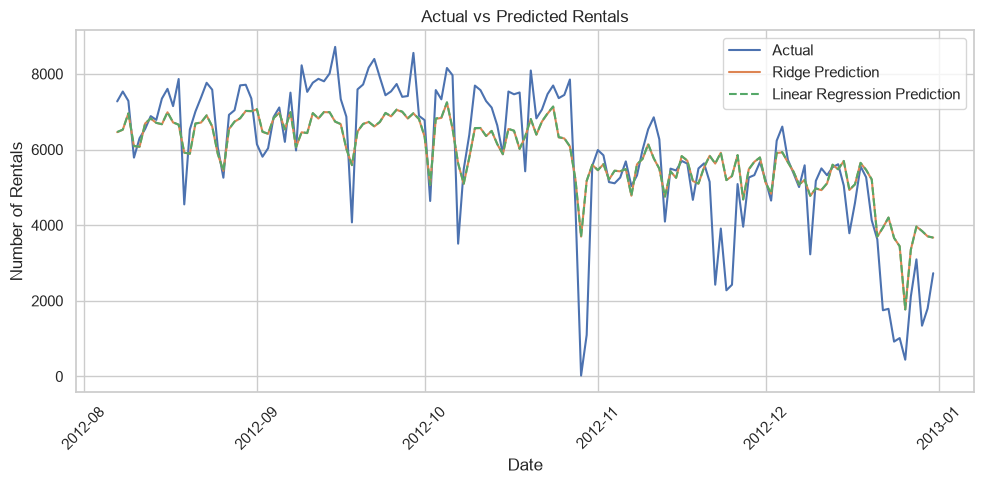

In [28]:
plt.figure(figsize=(10, 5))
plt.plot(test_df['dteday'], y_test, label='Actual')
plt.plot(test_df['dteday'], y_pred_ridge, label='Ridge Prediction')
plt.plot(test_df['dteday'], y_pred_lr,label='Linear Regression Prediction', linestyle='--')
plt.xlabel('Date')
plt.ylabel('Number of Rentals')
plt.title('Actual vs Predicted Rentals')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

## 12. Create Low and High Demand Labels

In [29]:
threshold = y_train.median()

y_train_class = (y_train > threshold).astype(int)
y_test_class = (y_test > threshold).astype(int)

print('Demand threshold:', threshold)
print('Training class counts:')
print(y_train_class.value_counts())
print('Testing class counts:')
print(y_test_class.value_counts())

Demand threshold: 4200.0
Training class counts:
cnt
0    292
1    292
Name: count, dtype: int64
Testing class counts:
cnt
1    123
0     24
Name: count, dtype: int64


## 13. Decision Tree

In [30]:
dt_model = DecisionTreeClassifier(max_depth=3, min_samples_leaf=5, random_state=42)
dt_model.fit(X_train_encoded, y_train_class)

y_pred_dt = dt_model.predict(X_test_encoded)

In [31]:
accuracy_dt = accuracy_score(y_test_class, y_pred_dt)
precision_dt = precision_score(y_test_class, y_pred_dt, zero_division=0)
recall_dt = recall_score(y_test_class, y_pred_dt, zero_division=0)
f1_dt = f1_score(y_test_class, y_pred_dt, average='macro', zero_division=0)

print('Decision Tree Results')
print('Accuracy:', accuracy_dt)
print('High-demand Precision:', precision_dt)
print('High-demand Recall:', recall_dt)
print('Macro F1 Score:', f1_dt)
print(classification_report(y_test_class, y_pred_dt, labels=[0, 1],
                            target_names=['Low', 'High'], zero_division=0))

Decision Tree Results
Accuracy: 0.8095238095238095
High-demand Precision: 0.9439252336448598
High-demand Recall: 0.8211382113821138
Macro F1 Score: 0.7203804347826087
              precision    recall  f1-score   support

         Low       0.45      0.75      0.56        24
        High       0.94      0.82      0.88       123

    accuracy                           0.81       147
   macro avg       0.70      0.79      0.72       147
weighted avg       0.86      0.81      0.83       147



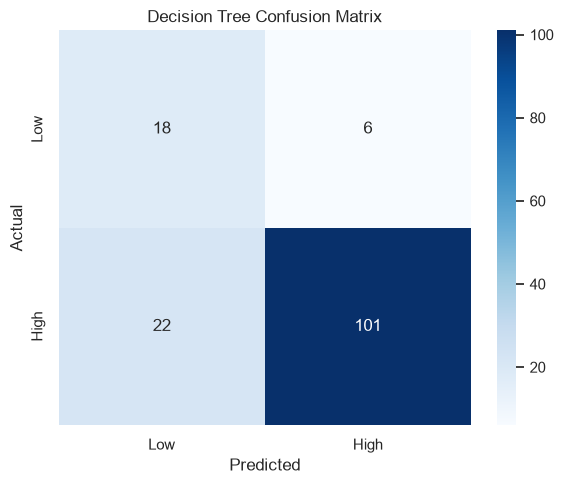

In [32]:
cm_dt = confusion_matrix(y_test_class, y_pred_dt, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Low', 'High'], yticklabels=['Low', 'High'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Decision Tree Confusion Matrix')
plt.tight_layout()
plt.show()

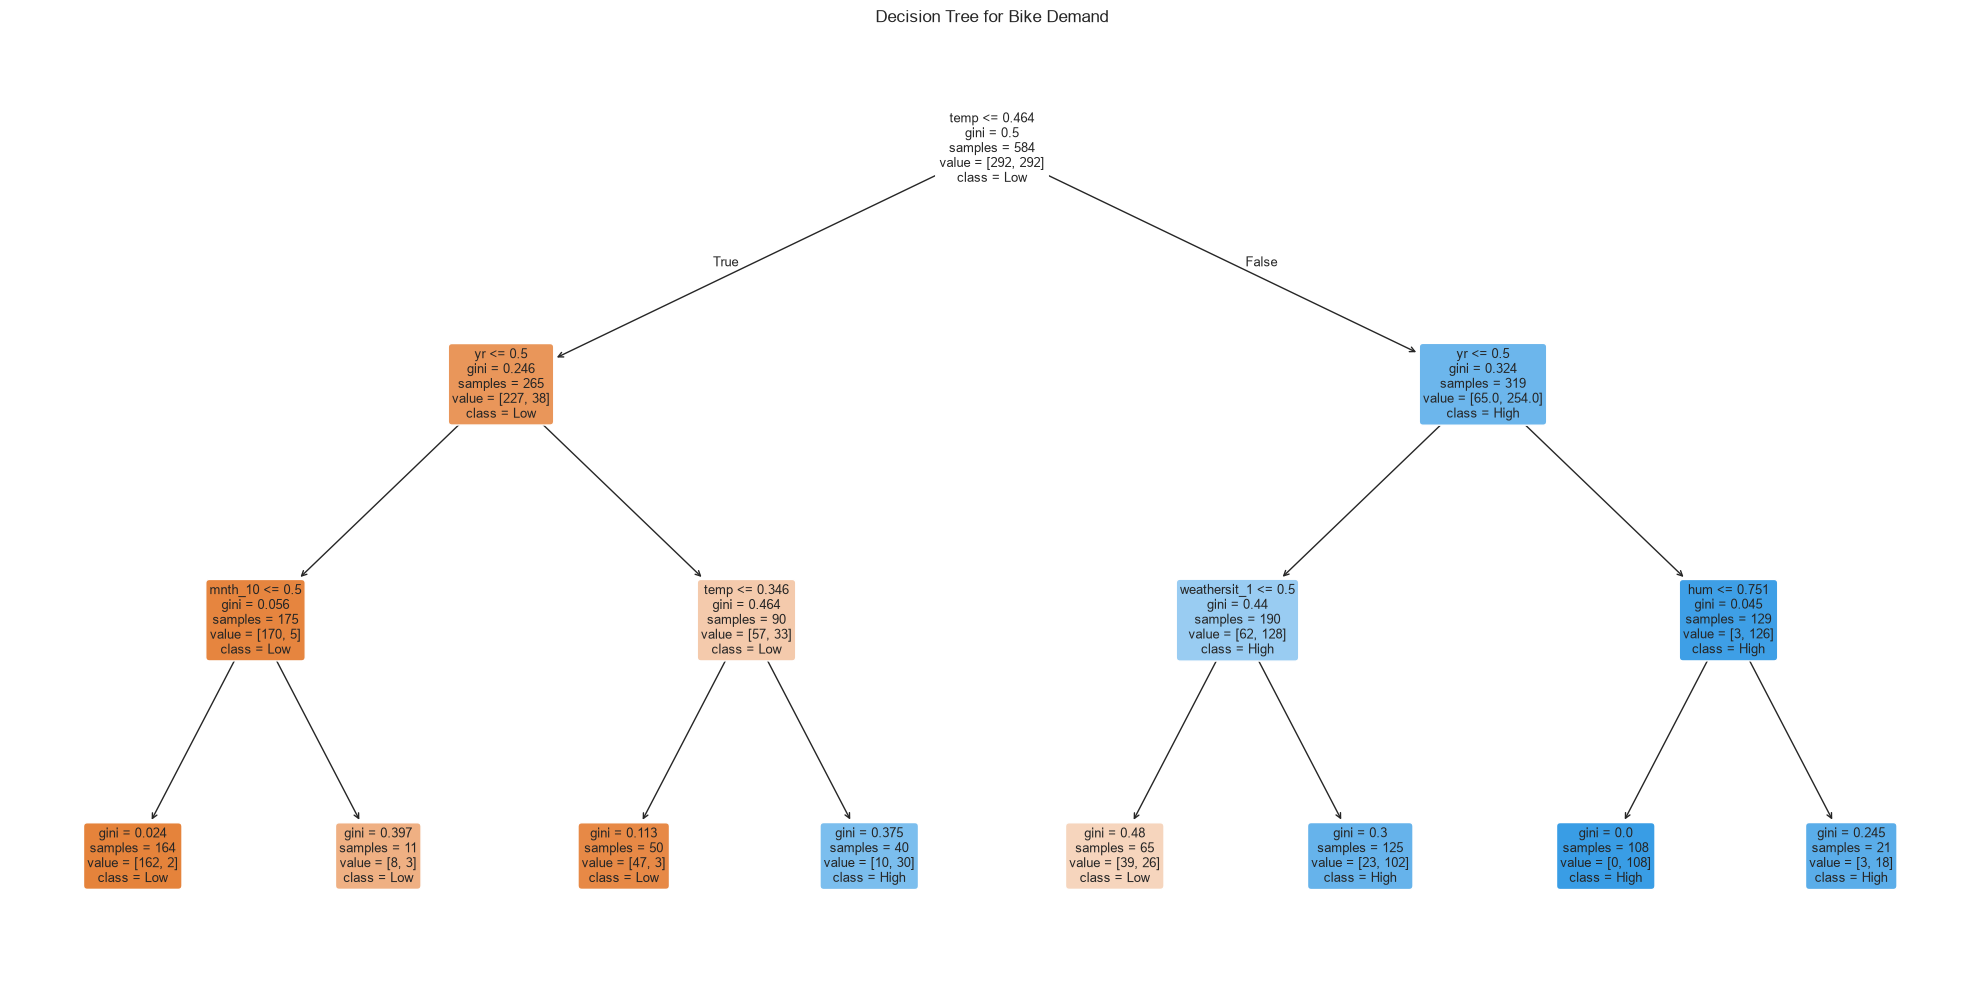

In [33]:
plt.figure(figsize=(20, 10))
plot_tree(dt_model, feature_names=X_train_encoded.columns,
          class_names=['Low', 'High'], filled=True, rounded=True, fontsize=9)
plt.title('Decision Tree for Bike Demand')
plt.tight_layout()
plt.show()

## 14. Linear SVM

In [34]:
linear_svm = SVC(kernel='linear', C=1)
linear_svm.fit(X_train_scaled, y_train_class)

y_pred_linear = linear_svm.predict(X_test_scaled)

In [35]:
accuracy_linear = accuracy_score(y_test_class, y_pred_linear)
precision_linear = precision_score(y_test_class, y_pred_linear, zero_division=0)
recall_linear = recall_score(y_test_class, y_pred_linear, zero_division=0)
f1_linear = f1_score(y_test_class, y_pred_linear, average='macro', zero_division=0)

print('Linear SVM Results')
print('Accuracy:', accuracy_linear)
print('High-demand Precision:', precision_linear)
print('High-demand Recall:', recall_linear)
print('Macro F1 Score:', f1_linear)
print(classification_report(y_test_class, y_pred_linear, labels=[0, 1],
                            target_names=['Low', 'High'], zero_division=0))

Linear SVM Results
Accuracy: 0.8979591836734694
High-demand Precision: 0.8970588235294118
High-demand Recall: 0.991869918699187
Macro F1 Score: 0.7567567567567568
              precision    recall  f1-score   support

         Low       0.91      0.42      0.57        24
        High       0.90      0.99      0.94       123

    accuracy                           0.90       147
   macro avg       0.90      0.70      0.76       147
weighted avg       0.90      0.90      0.88       147



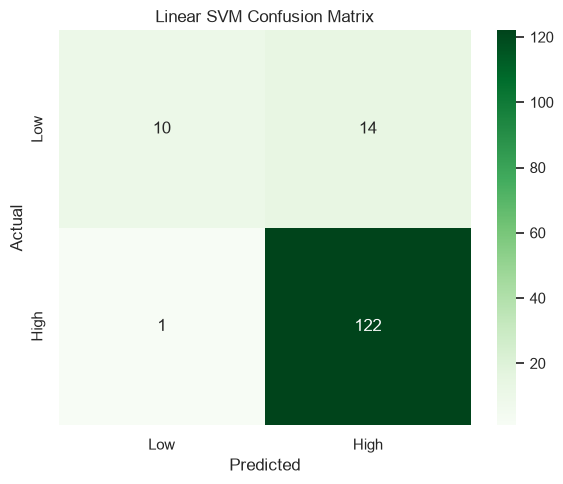

In [36]:
cm_linear = confusion_matrix(y_test_class, y_pred_linear, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(cm_linear, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Low', 'High'], yticklabels=['Low', 'High'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Linear SVM Confusion Matrix')
plt.tight_layout()
plt.show()

## 15. RBF SVM

In [37]:
rbf_svm = SVC(kernel='rbf', C=1, gamma='scale')
rbf_svm.fit(X_train_scaled, y_train_class)

y_pred_rbf = rbf_svm.predict(X_test_scaled)

In [38]:
accuracy_rbf = accuracy_score(y_test_class, y_pred_rbf)
precision_rbf = precision_score(y_test_class, y_pred_rbf, zero_division=0)
recall_rbf = recall_score(y_test_class, y_pred_rbf, zero_division=0)
f1_rbf = f1_score(y_test_class, y_pred_rbf, average='macro', zero_division=0)

print('RBF SVM Results')
print('Accuracy:', accuracy_rbf)
print('High-demand Precision:', precision_rbf)
print('High-demand Recall:', recall_rbf)
print('Macro F1 Score:', f1_rbf)
print(classification_report(y_test_class, y_pred_rbf, labels=[0, 1],
                            target_names=['Low', 'High'], zero_division=0))

RBF SVM Results
Accuracy: 0.6190476190476191
High-demand Precision: 0.971830985915493
High-demand Recall: 0.5609756097560976
Macro F1 Score: 0.5756701030927835
              precision    recall  f1-score   support

         Low       0.29      0.92      0.44        24
        High       0.97      0.56      0.71       123

    accuracy                           0.62       147
   macro avg       0.63      0.74      0.58       147
weighted avg       0.86      0.62      0.67       147



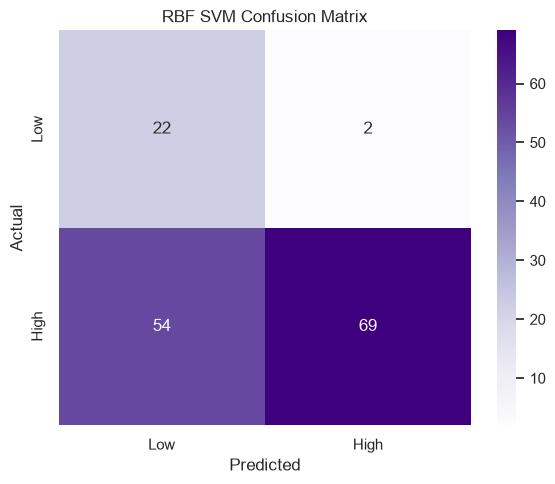

In [39]:
cm_rbf = confusion_matrix(y_test_class, y_pred_rbf, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(cm_rbf, annot=True, fmt='d', cmap='Purples',
            xticklabels=['Low', 'High'], yticklabels=['Low', 'High'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('RBF SVM Confusion Matrix')
plt.tight_layout()
plt.show()

## 16. Compare Classification Models

In [40]:
baseline_class = np.ones(len(y_test_class), dtype=int)

accuracy_baseline = accuracy_score(y_test_class, baseline_class)
precision_baseline = precision_score(y_test_class, baseline_class, zero_division=0)
recall_baseline = recall_score(y_test_class, baseline_class, zero_division=0)
f1_baseline = f1_score(y_test_class, baseline_class, average='macro', zero_division=0)

classification_results = pd.DataFrame({
    'Model': ['Always High', 'Decision Tree', 'Linear SVM', 'RBF SVM'],
    'Accuracy': [accuracy_baseline, accuracy_dt, accuracy_linear, accuracy_rbf],
    'High Precision': [precision_baseline, precision_dt, precision_linear, precision_rbf],
    'High Recall': [recall_baseline, recall_dt, recall_linear, recall_rbf],
    'Macro F1': [f1_baseline, f1_dt, f1_linear, f1_rbf]
})

classification_results.round(3)

,Model,Accuracy,High Precision,High Recall,Macro F1
0,Always High,0.837,0.837,1.000,0.456
1,Decision Tree,0.810,0.944,0.821,0.720
2,Linear SVM,0.898,0.897,0.992,0.757
3,RBF SVM,0.619,0.972,0.561,0.576


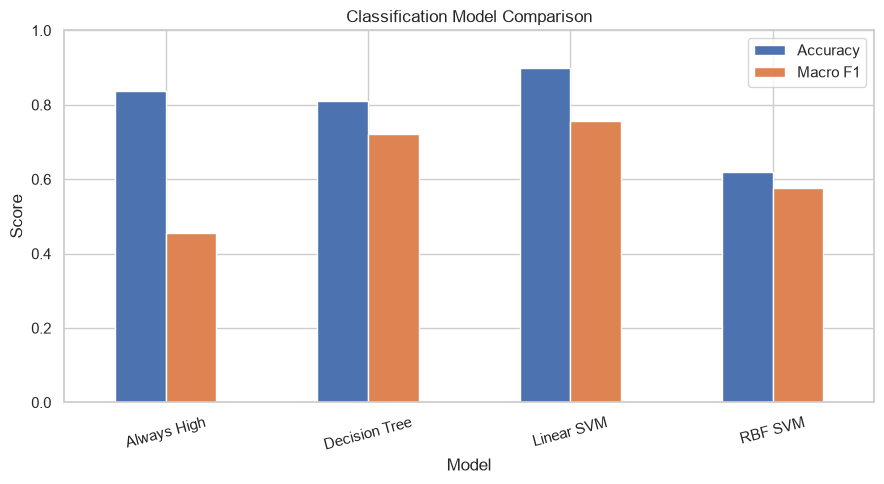

In [41]:
classification_results.plot(x='Model', y=['Accuracy', 'Macro F1'], kind='bar', figsize=(9, 5))
plt.title('Classification Model Comparison')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 17. Training vs Testing Accuracy

In [42]:
print('Decision Tree Training Accuracy:', dt_model.score(X_train_encoded, y_train_class))
print('Decision Tree Testing Accuracy:', accuracy_dt)

print('Linear SVM Training Accuracy:', linear_svm.score(X_train_scaled, y_train_class))
print('Linear SVM Testing Accuracy:', accuracy_linear)

print('RBF SVM Training Accuracy:', rbf_svm.score(X_train_scaled, y_train_class))
print('RBF SVM Testing Accuracy:', accuracy_rbf)

Decision Tree Training Accuracy: 0.8801369863013698
Decision Tree Testing Accuracy: 0.8095238095238095
Linear SVM Training Accuracy: 0.916095890410959
Linear SVM Testing Accuracy: 0.8979591836734694
RBF SVM Training Accuracy: 0.9212328767123288
RBF SVM Testing Accuracy: 0.6190476190476191


## 18. Predict for a New Day

In [43]:
new_day = pd.DataFrame({
    'temp': [0.40],
    'hum': [0.80],
    'windspeed': [0.55],
    'season': [3],
    'yr': [0],
    'mnth': [8],
    'holiday': [1],
    'weekday': [0],
    'workingday': [0],
    'weathersit': [3]
})

new_day

,temp,hum,windspeed,season,yr,mnth,holiday,weekday,workingday,weathersit
0,0.4,0.8,0.55,3,0,8,1,0,0,3


In [44]:
new_day_encoded = pd.get_dummies(new_day, columns=categorical_columns, dtype=int)
new_day_encoded = new_day_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)

new_day_scaled = scaler.transform(new_day_encoded)

count_prediction = ridge_model.predict(new_day_scaled)
tree_prediction = dt_model.predict(new_day_encoded)
linear_prediction = linear_svm.predict(new_day_scaled)
rbf_prediction = rbf_svm.predict(new_day_scaled)

# Prevent a negative count being displayed. Evaluation above uses raw predictions.
print('Estimated Bike Rentals:', round(max(0, count_prediction[0])))

class_names = ['Low', 'High']
print('Decision Tree Demand:', class_names[tree_prediction[0]])
print('Linear SVM Demand:', class_names[linear_prediction[0]])
print('RBF SVM Demand:', class_names[rbf_prediction[0]])
print('High demand means more than', threshold, 'rentals per day.')

Estimated Bike Rentals: 0
Decision Tree Demand: Low
Linear SVM Demand: Low
RBF SVM Demand: Low
High demand means more than 4200.0 rentals per day.
